# UCS420 Cognitive Computing — Lab Assignment 8
## NLP using Python-II

**Topics:** text feature extraction, similarity, sentiment analysis, and text generation.

## Q1–Q2: Text preprocessing, frequency, stemming, and lemmatization

In [1]:
%pip install nltk scikit-learn textblob wordcloud matplotlib tensorflow

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
[nltk_data] Error loading punkt: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>
[nltk_data] Error loading punkt_tab: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>
[nltk_data] Error loading stopwords: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>
[nltk_data] Error loading wordnet: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>


False

In [2]:
import re
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

paragraph = """
Artificial intelligence is transforming modern technology at an incredible pace. 
Smartphones, cars, and even home appliances now use intelligent algorithms every day! 
Machine learning models analyze massive amounts of data to make accurate predictions. 
However, ethical concerns around privacy and automation still need careful attention. 
In the coming decade, AI will likely reshape healthcare, education, and entertainment.
"""

# 1. Convert to lowercase and remove punctuation using re
clean_text = re.sub(r'[^\w\s]', '', paragraph.lower())
print("Cleaned Text:\n", clean_text)

# 2. Tokenize into sentences and words
sentences = sent_tokenize(paragraph)
words = word_tokenize(clean_text)
print("\nSentences:", sentences)
print("\nWords:", words)

# 3. Compare split() vs word_tokenize() on original text
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)
print("\nUsing split() (first 15):", split_tokens[:15])
print("Using word_tokenize() (first 15):", nltk_tokens[:15])

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nFiltered Words (No Stopwords):", filtered_words)

# 5. Word frequency distribution
fdist = FreqDist(filtered_words)
print("\nTop 10 Most Common Words:", fdist.most_common(10))

Cleaned Text:
 
artificial intelligence is transforming modern technology at an incredible pace 
smartphones cars and even home appliances now use intelligent algorithms every day 
machine learning models analyze massive amounts of data to make accurate predictions 
however ethical concerns around privacy and automation still need careful attention 
in the coming decade ai will likely reshape healthcare education and entertainment


Sentences: ['\nArtificial intelligence is transforming modern technology at an incredible pace.', 'Smartphones, cars, and even home appliances now use intelligent algorithms every day!', 'Machine learning models analyze massive amounts of data to make accurate predictions.', 'However, ethical concerns around privacy and automation still need careful attention.', 'In the coming decade, AI will likely reshape healthcare, education, and entertainment.']

Words: ['artificial', 'intelligence', 'is', 'transforming', 'modern', 'technology', 'at', 'an', 'incredible

In [12]:
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# 1. Extract words with only alphabets
alpha_words = re.findall(r'[a-zA-Z]+', paragraph.lower())

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered = [w for w in alpha_words if w not in stop_words]

# 3. Stemming with PorterStemmer
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in filtered]

# 4. Lemmatization with WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in filtered]

# 5. Compare outputs side by side
print(f"{'Original':<15} {'Stemmed':<15} {'Lemmatized':<15}")
print()
for orig, st, lem in zip(filtered[:15], stemmed[:15], lemmatized[:15]):
    print(f"{orig:<15} {st:<15} {lem:<15}")

Original        Stemmed         Lemmatized     

artificial      artifici        artificial     
intelligence    intellig        intelligence   
transforming    transform       transforming   
modern          modern          modern         
technology      technolog       technology     
incredible      incred          incredible     
pace            pace            pace           
smartphones     smartphon       smartphones    
cars            car             car            
even            even            even           
home            home            home           
appliances      applianc        appliance      
use             use             use            
intelligent     intellig        intelligent    
algorithms      algorithm       algorithm      


**Q2 comparison:** Stemming mechanically trims word endings, so its outputs can be fragments (for example, *gardeners* may reduce to *garden* while some other stems are not dictionary words). Lemmatization returns dictionary forms and is easier to interpret, but usually needs more linguistic knowledge. Stemming is useful for fast search/index matching; lemmatization is preferable when readable, linguistically meaningful terms matter.

## Q3: Bag of Words and TF-IDF keywords
Three short original texts are vectorized. For each text, the three highest TF-IDF terms are printed and interpreted as terms that distinguish it from the other texts.

In [13]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The new smartphone has an amazing camera and fast battery charging.",
    "Battery life on this laptop is terrible, though the screen is bright.",
    "Great camera quality and lightweight design make this phone worth buying."
]

# 1. Bag of Words
cv = CountVectorizer(stop_words='english')
bow = cv.fit_transform(texts)
print("BoW Feature Names:", cv.get_feature_names_out())
print("BoW Matrix:\n", bow.toarray())

# 2. TF-IDF
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)
feature_names = tfidf.get_feature_names_out()

# 3. Top 3 keywords per text using TF-IDF
import pandas as pd

df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)

for i in range(len(texts)):
    print(f"\nText {i+1} Top 3 Keywords:")
    print(df.iloc[i].nlargest(3))

BoW Feature Names: ['amazing' 'battery' 'bright' 'buying' 'camera' 'charging' 'design' 'fast'
 'great' 'laptop' 'life' 'lightweight' 'make' 'new' 'phone' 'quality'
 'screen' 'smartphone' 'terrible' 'worth']
BoW Matrix:
 [[1 1 0 0 1 1 0 1 0 0 0 0 0 1 0 0 0 1 0 0]
 [0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 1 0]
 [0 0 0 1 1 0 1 0 1 0 0 1 1 0 1 1 0 0 0 1]]

Text 1 Top 3 Keywords:
amazing     0.403016
charging    0.403016
fast        0.403016
Name: 0, dtype: float64

Text 2 Top 3 Keywords:
bright    0.423394
laptop    0.423394
life      0.423394
Name: 1, dtype: float64

Text 3 Top 3 Keywords:
buying    0.341426
design    0.341426
great     0.341426
Name: 2, dtype: float64


## Q4: Similarity between two technology descriptions
The descriptions each have four lines. They are lowercased and tokenized into alphabetic terms before comparing word-set overlap with Jaccard and weighted term overlap with TF-IDF cosine similarity.

In [18]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_ai = """
Artificial intelligence enables machines to learn from data and make decisions.
Deep learning and neural networks power modern AI applications.
AI is widely used in healthcare, finance, and autonomous vehicles.
It focuses on pattern recognition, automation, and predictive analytics.
"""

text_blockchain = """
Blockchain is a decentralized digital ledger that records transactions securely.
It uses cryptography to ensure data integrity without a central authority.
Blockchain is widely used in finance, supply chains, and cryptocurrencies.
It focuses on transparency, security, and immutable data storage.
"""

# 1. Preprocess and tokenize
def preprocess(text):
    clean = re.sub(r'[^\w\s]', '', text.lower())
    return clean.split()

tokens_ai = set(preprocess(text_ai))
tokens_bc = set(preprocess(text_blockchain))

# 2a. Jaccard Similarity
jaccard = len(tokens_ai & tokens_bc) / len(tokens_ai | tokens_bc)
print("Jaccard Similarity:", round(jaccard, 4))

# 2b. Cosine Similarity
tfidf_vec = TfidfVectorizer(stop_words='english')
vecs = tfidf_vec.fit_transform([text_ai, text_blockchain])
cos_sim = cosine_similarity(vecs[0:1], vecs[1:2])[0][0]
print("Cosine Similarity:", round(cos_sim, 4))

Jaccard Similarity: 0.1897
Cosine Similarity: 0.1093


## Q5: Review sentiment and positive-review word cloud
TextBlob polarity is in [-1, 1] and subjectivity is in [0, 1]. The neutral band below is explicitly set to polarity values from -0.05 through 0.05.

Review 1: Positive (Polarity: 0.43, Subjectivity: 0.69)
Review 2: Negative (Polarity: -0.39, Subjectivity: 0.66)
Review 3: Negative (Polarity: -0.15, Subjectivity: 0.40)
Review 4: Positive (Polarity: 0.41, Subjectivity: 0.70)
Review 5: Positive (Polarity: 0.33, Subjectivity: 0.50)


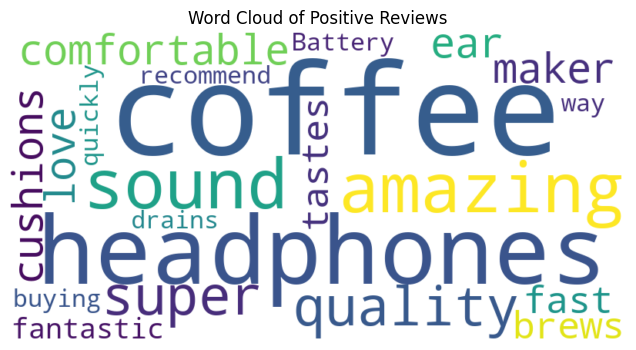

In [20]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "The headphones have amazing sound quality and super comfortable ear cushions.",
    "Delivery was late and the packaging arrived completely damaged. Very disappointed.",
    "The product works as described. It is an average item for the price.",
    "I love this coffee maker! It brews fast and the coffee tastes fantastic.",
    "Battery drains way too quickly. Would not recommend buying this."
]

positive_reviews = []

# 1 & 2. Find Polarity, Subjectivity, and Classify
for i, review in enumerate(reviews, 1):
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity
    
    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"
        
    print(f"Review {i}: {sentiment} (Polarity: {polarity:.2f}, Subjectivity: {subjectivity:.2f})")

# 3. Word Cloud for all Positive Reviews
pos_text = " ".join(positive_reviews)
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(pos_text)

plt.figure(figsize=(8, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()

## Q6: Next-word generation with a small LSTM
The model learns next-word patterns from an original paragraph of about 100 words. This is a demonstration on a tiny corpus, not a general-purpose language model. TensorFlow/Keras is required for this section.

In [21]:
%pip install --upgrade tensorflow


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 880.7 kB/s eta 0:06:39
   ---------------------------------------- 0.5/351.2 MB 880.7 kB/s eta 0:06:39
   ---------------------------------------- 0.8/351.2 MB 767.3 kB/s eta 0:07:37
   ---------------------------------------- 0.8/351.2 MB 767.3 kB/s eta 0:07:37
   ---------------------------------------- 0.8/351.2 MB 767.3 kB/s eta 0:07:37
   ---------------------------

In [19]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Training paragraph (~100 words)
text = """
Machine learning is a powerful branch of artificial intelligence that helps computers learn from data.
Instead of following strict rules, machine learning models discover patterns and make smart predictions.
Deep learning uses neural networks to solve complex problems like image recognition and language translation.
Natural language processing allows machines to read, understand, and generate human language.
With enough data and training, a simple neural network can predict the next word in a sentence.
Learning about artificial intelligence and deep learning is both exciting and rewarding for students.
Technology continues to evolve every day with new models and creative ideas.
"""

# 1. Tokenize text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])
total_words = len(tokenizer.word_index) + 1

# 2. Create input sequences
sequences = []
tokens = tokenizer.texts_to_sequences([text])[0]
for i in range(1, len(tokens)):
    sequences.append(tokens[:i+1])

# Pad sequences
max_len = max(len(x) for x in sequences)
sequences = np.array(pad_sequences(sequences, maxlen=max_len, padding='pre'))

# Split into X and y, and one-hot encode y
X, y = sequences[:, :-1], sequences[:, -1]
y = to_categorical(y, num_classes=total_words)

# Build simple LSTM model
model = Sequential([
    Embedding(total_words, 10, input_length=max_len - 1),
    LSTM(100),
    Dense(total_words, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# 3. Train the model
model.fit(X, y, epochs=150, verbose=0)
print("Model training complete!")

# Generate 2-3 new lines from seed words
def generate_text(seed_text, next_words=10):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_len - 1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
        output_word = tokenizer.index_word.get(predicted, "")
        seed_text += " " + output_word
    return seed_text

print("\nGenerated Line 1:", generate_text("machine learning", next_words=10))
print("Generated Line 2:", generate_text("deep learning", next_words=10))
print("Generated Line 3:", generate_text("natural language", next_words=10))

ImportError: Traceback (most recent call last):
  File "c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\tensorflow\python\__init__.py", line 66, in <module>
    from tensorflow.python import pywrap_tensorflow
  File "c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 28, in <module>
    _pywrap_tensorflow = swig_import_helper()
  File "c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 15, in swig_import_helper
    import imp
ModuleNotFoundError: No module named 'imp'


Failed to load the native TensorFlow runtime.

See https://github.com/tensorflow/tensorflow/blob/master/tensorflow/g3doc/get_started/os_setup.md#import_error

for some common reasons and solutions.  Include the entire stack trace
above this error message when asking for help.

**Observation:** A tiny training paragraph produces limited, repetitive generations because the model only sees a small vocabulary and few contexts. A larger and more varied corpus, more training examples, and sampling rather than always selecting the most likely next word would improve diversity.